In [1]:
!pip install pvlib
!pip install nrel-pysam

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 36.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.3/47.3 MB 10.6 MB/s eta 0:00:00


In [2]:
import pvlib

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

In [3]:
# latitude, longitude, name, altitude, timezone
latitude, longitude, name, altitude, timezone = 9.376950, -83.701886, 'CoopeAgri Perez Zeledon', 704, 'America/Costa_Rica'

In [4]:
# get the module and inverter specifications from SAM (version actualizada en GitHub)
url_modules = "https://raw.githubusercontent.com/NREL/SAM/refs/heads/develop/deploy/libraries/CEC%20Modules.csv"
url_inverters = "https://raw.githubusercontent.com/NREL/SAM/refs/heads/develop/deploy/libraries/CEC%20Inverters.csv"

cec_modules = pvlib.pvsystem.retrieve_sam(path=url_modules)

cec_inverters = pvlib.pvsystem.retrieve_sam(path=url_inverters)

/usr/local/lib/python3.13/dist-packages/pvlib/pvsystem.py:2339: UserWarning: Original names contain 36 duplicate(s).
  warnings.warn('Original names contain %d duplicate(s).' % n_duplicates)
/usr/local/lib/python3.13/dist-packages/pvlib/pvsystem.py:2343: UserWarning: Normalized names contain 36 duplicate(s).
  warnings.warn(


In [5]:
cec_modules

,Ablytek_6MN6A270,Ablytek_6MN6A275,Ablytek_6MN6A280,Ablytek_6MN6A285,Ablytek_6MN6A290,Advance_Power_API_P210,Advance_Power_API_P215,Advance_Power_API_P220,Advance_Power_API_M225,Advance_Power_API_P225,...,ZNSHINE_PV_TECH_Co_Ltd_ZXM8_GPLDD132_695_N,ZNSHINE_PV_TECH_Co_Ltd_ZXM8_GPLDD132_700_N,ZNSHINE_PV_TECH_Co_Ltd_ZXM8_GPLDD132_705_N,ZNSHINE_PV_TECH_Co_Ltd_ZXM8_GPLDD132_710_N,ZNSHINE_PV_TECH_Co_Ltd_ZXM8_GPLDD132_715_N,ZNSHINE_PV_TECH_Co_Ltd_ZXM8_GPLDD132_720_N,ZNSHINE_PV_TECH_Co_Ltd_ZXM8_GPLDD132_725_N,ZNSHINE_PV_TECH_Co_Ltd_ZXM8_GPLDD132_730_N,ZNSHINE_PV_TECH_Co_Ltd_ZXM8_GPLDD132_735_N,ZNSHINE_PV_TECH_Co_Ltd_ZXM8_GPLDD132_740_N
Manufacturer,Ablytek,Ablytek,Ablytek,Ablytek,Ablytek,Advance Power,Advance Power,Advance Power,Advance Power,Advance Power,...,ZNSHINE PV-TECH Co Ltd,ZNSHINE PV-TECH Co Ltd,ZNSHINE PV-TECH Co Ltd,ZNSHINE PV-TECH Co Ltd,ZNSHINE PV-TECH Co Ltd,ZNSHINE PV-TECH Co Ltd,ZNSHINE PV-TECH Co Ltd,ZNSHINE PV-TECH Co Ltd,ZNSHINE PV-TECH Co Ltd,ZNSHINE PV-TECH Co Ltd
Technology,Mono-c-Si,Mono-c-Si,Mono-c-Si,Mono-c-Si,Mono-c-Si,Multi-c-Si,Multi-c-Si,Multi-c-Si,Mono-c-Si,Multi-c-Si,...,Mono-c-Si,Mono-c-Si,Mono-c-Si,Mono-c-Si,Mono-c-Si,Mono-c-Si,Mono-c-Si,Mono-c-Si,Mono-c-Si,Mono-c-Si
Bifacial,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,1,1
STC,270.0,275.0,280.0,285.0,290.0,210.0,215.0,220.0,225.0,225.0,...,695.0,700.0,705.0,710.0,715.0,720.0,725.0,730.0,735.0,740.0
PTC,242.1,246.7,251.3,256.0,260.6,186.8,191.3,195.9,200.7,200.5,...,664.1,669.0,673.9,678.8,683.6,688.5,693.4,698.3,703.2,708.0
A_c,1.6269,1.6269,1.6269,1.6269,1.6269,1.6378,1.6378,1.6378,1.6378,1.6378,...,3.1,3.1,3.1,3.1,3.1,3.1,3.1,3.1,3.1,3.1
Length,1.64,1.64,1.64,1.64,1.64,1.646,1.646,1.646,1.646,1.646,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Width,0.992,0.992,0.992,0.992,0.992,0.995,0.995,0.995,0.995,0.995,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
N_s,60.0,60.0,60.0,60.0,60.0,60.0,60.0,60.0,60.0,60.0,...,66.0,66.0,66.0,66.0,66.0,66.0,66.0,66.0,66.0,66.0
I_sc_ref,9.34,9.42,9.51,9.59,9.67,7.6,7.83,7.95,8.11,8.1,...,18.23,18.27,18.31,18.35,18.39,18.43,18.47,18.51,18.55,18.95


In [6]:
cec_modules.columns[cec_modules.columns.str.contains('AIKO', case=False)]

Index([], dtype='object')

In [7]:
cec_inverters.columns[cec_inverters.columns.str.contains('SCA25KTL', case=False)]

Index(['Chint_Power_Systems_America__CPS_SCA25KTL_DO_R_US_480_{480V}', 'Chint_Power_Systems_America__CPS_SCA25KTL_DO_US_208_{208V}'], dtype='object')

In [8]:
module = cec_modules['AEG_SOLAR_ENERGY_SRL_ALPS54D30_450_TP']

inverter = cec_inverters['Chint_Power_Systems_America__CPS_SCA25KTL_DO_US_208_{208V}']

temperature_model_parameters = pvlib.temperature.TEMPERATURE_MODEL_PARAMETERS['sapm']['open_rack_glass_polymer']

In [9]:
module

,AEG_SOLAR_ENERGY_SRL_ALPS54D30_450_TP
Manufacturer,AEG SOLAR ENERGY SRL
Technology,Mono-c-Si
Bifacial,0
STC,450.0
PTC,424.6
A_c,1.99
Length,NaN
Width,NaN
N_s,54.0
I_sc_ref,14.28


In [10]:
inverter

,Chint_Power_Systems_America__CPS_SCA25KTL_DO_US_208_{208V}
Vac,208
Pso,79.0356
Paco,25000.0
Pdco,25971.3
Vdco,575.0
C0,-0.000001
C1,0.000016
C2,0.001805
C3,0.000251
Pnt,2.9


In [11]:
temperature_model_parameters

{'a': -3.56, 'b': -0.075, 'deltaT': 3}

In [12]:
# parametros del modelo de un diodo del AIKO-A450-MAH54Mb a partir de su hoja de datos
I_L_ref, I_o_ref, R_s, R_sh_ref, a_ref, Adjust = pvlib.ivtools.sdm.fit_cec_sam(
    'monoSi', v_mp=33.70, i_mp=13.36, v_oc=40.69, i_sc=14.12,
    alpha_sc=0.0005 * 14.12, beta_voc=-0.0022 * 40.69, gamma_pmp=-0.26,
    cells_in_series=54)

In [13]:
my_new_module = module.copy()
my_new_module["Manufacturer"] = "AIKO"
my_new_module["STC"] = 450.0
my_new_module["A_c"] = 1.992
my_new_module["Length"] = 1.757
my_new_module["Width"] = 1.134
my_new_module["N_s"] = 54
my_new_module["I_sc_ref"] = 14.12
my_new_module["V_oc_ref"] = 40.69
my_new_module["I_mp_ref"] = 13.36
my_new_module["V_mp_ref"] = 33.70
my_new_module["alpha_sc"] = 0.0005 * 14.12
my_new_module["beta_oc"] = -0.0022 * 40.69
my_new_module["gamma_pmp"] = -0.26
my_new_module["T_NOCT"] = 47
my_new_module["a_ref"] = a_ref
my_new_module["I_L_ref"] = I_L_ref
my_new_module["I_o_ref"] = I_o_ref
my_new_module["R_s"] = R_s
my_new_module["R_sh_ref"] = R_sh_ref
my_new_module["Adjust"] = Adjust
my_new_module.name = "AIKO-A450-MAH54Mb"
my_new_module

,AIKO-A450-MAH54Mb
Manufacturer,AIKO
Technology,Mono-c-Si
Bifacial,0
STC,450.0
PTC,424.6
A_c,1.992
Length,1.757
Width,1.134
N_s,54
I_sc_ref,14.12


In [14]:
check = pvlib.pvsystem.singlediode(*pvlib.pvsystem.calcparams_cec(
    np.array([1000.0, 1000.0]), np.array([25.0, 65.0]),
    my_new_module['alpha_sc'], my_new_module['a_ref'], my_new_module['I_L_ref'],
    my_new_module['I_o_ref'], my_new_module['R_sh_ref'], my_new_module['R_s'],
    my_new_module['Adjust']))
pd.DataFrame(check).set_axis(['25 C', '65 C'])

,i_sc,v_oc,i_mp,v_mp,p_mp,i_x,i_xx
25 C,14.120000,40.690000,13.360000,33.700000,450.232000,14.008598,9.577416
65 C,14.398662,37.035044,13.480801,29.825618,402.073232,14.296761,9.516789


In [15]:
# generacion mensual del proyecto (kWh) y HSP a 10 grados
months = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Set', 'Oct', 'Nov', 'Dic']

days = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])

project = pd.Series([20092.5, 20066.2, 22394.7, 19094.3, 17261.6, 16378.4,
                     16613.2, 17637.5, 18305.2, 17558.5, 15827.0, 18296.1], index=months)

project_hsp = pd.Series([4.787, 5.300, 5.354, 4.723, 4.128, 4.043,
                         3.966, 4.211, 4.514, 4.187, 3.898, 4.360], index=months)

In [16]:
weather = pvlib.iotools.get_pvgis_tmy(latitude, longitude, map_variables=True)[0]
weather.index.name = 'utc_time'

In [17]:
weather

,temp_air,relative_humidity,ghi,dni,dhi,IR(h),wind_speed,wind_direction,pressure
utc_time,,,,,,,,,
1990-01-01 00:00:00+00:00,22.11,85.01,0.00,0.00,0.00,363.14,0.91,302.0,94580.0
1990-01-01 01:00:00+00:00,21.82,85.99,0.00,0.00,0.00,363.06,0.86,23.0,94600.0
1990-01-01 02:00:00+00:00,21.53,86.96,0.00,0.00,0.00,362.97,0.81,44.0,94690.0
1990-01-01 03:00:00+00:00,21.25,87.94,0.00,0.00,0.00,362.89,0.76,54.0,94750.0
1990-01-01 04:00:00+00:00,20.96,88.92,0.00,0.00,0.00,362.81,0.71,46.0,94750.0
...,...,...,...,...,...,...,...,...,...
1990-12-31 19:00:00+00:00,23.54,80.13,561.55,494.46,172.45,363.56,1.15,251.0,93830.0
1990-12-31 20:00:00+00:00,23.25,81.10,477.40,504.93,136.20,363.48,1.10,264.0,93760.0
1990-12-31 21:00:00+00:00,22.97,82.08,298.15,343.67,121.45,363.39,1.05,273.0,93720.0


In [18]:
system = {'module': my_new_module, 'inverter': inverter,
          'surface_azimuth': 180, 'surface_tilt': 10, 'albedo': 0.12,
          'modules_per_string': 17, 'strings_per_inverter': [5, 5, 4, 4, 4]}

# perdidas del factor de rendimiento del proyecto que no calcula el modelo
soiling = 0.03
dc_losses = (1 - 0.02) * (1 - 0.02) * (1 - 0.01)

In [19]:
solpos = pvlib.solarposition.get_solarposition(
    time=weather.index,
    latitude=latitude,
    longitude=longitude,
    altitude=altitude,
    temperature=weather["temp_air"],
    pressure=pvlib.atmosphere.alt2pres(altitude),
)
dni_extra = pvlib.irradiance.get_extra_radiation(weather.index)
aoi = pvlib.irradiance.aoi(
    system['surface_tilt'],
    system['surface_azimuth'],
    solpos["apparent_zenith"],
    solpos["azimuth"],
)
total_irradiance = pvlib.irradiance.get_total_irradiance(
    system['surface_tilt'],
    system['surface_azimuth'],
    solpos['apparent_zenith'],
    solpos['azimuth'],
    weather['dni'],
    weather['ghi'],
    weather['dhi'],
    dni_extra=dni_extra,
    albedo=system['albedo'],
    model='haydavies',
)
cell_temperature = pvlib.temperature.sapm_cell(
    total_irradiance['poa_global'],
    weather["temp_air"],
    weather["wind_speed"],
    **temperature_model_parameters,
)
iam_diffuse = pvlib.iam.marion_diffuse('physical', system['surface_tilt'])
effective_irradiance = (total_irradiance['poa_direct'] * pvlib.iam.physical(aoi)
                        + total_irradiance['poa_sky_diffuse'] * iam_diffuse['sky']
                        + total_irradiance['poa_ground_diffuse'] * iam_diffuse['ground']) * (1 - soiling)
with np.errstate(divide='ignore', invalid='ignore'):
    dc = pvlib.pvsystem.singlediode(*pvlib.pvsystem.calcparams_cec(
        effective_irradiance, cell_temperature,
        my_new_module['alpha_sc'], my_new_module['a_ref'], my_new_module['I_L_ref'],
        my_new_module['I_o_ref'], my_new_module['R_sh_ref'], my_new_module['R_s'],
        my_new_module['Adjust']))
dc = dc.fillna(0).clip(lower=0)
ac = 0
for n_strings in system['strings_per_inverter']:
    v_dc = system['modules_per_string'] * dc['v_mp']
    p_dc = n_strings * system['modules_per_string'] * dc['p_mp'] * dc_losses
    ac = ac + pvlib.inverter.sandia(v_dc, p_dc, inverter).clip(lower=0)

In [20]:
solpos

,apparent_zenith,zenith,apparent_elevation,elevation,azimuth,equation_of_time
utc_time,,,,,,
1990-01-01 00:00:00+00:00,98.653048,98.653048,-8.653048,-8.653048,247.904443,-3.286217
1990-01-01 01:00:00+00:00,112.416320,112.416320,-22.416320,-22.416320,248.840746,-3.306034
1990-01-01 02:00:00+00:00,126.199515,126.199515,-36.199515,-36.199515,248.246580,-3.325842
1990-01-01 03:00:00+00:00,139.817575,139.817575,-49.817575,-49.817575,245.225360,-3.345641
1990-01-01 04:00:00+00:00,152.836769,152.836769,-62.836769,-62.836769,236.861915,-3.365431
...,...,...,...,...,...,...
1990-12-31 19:00:00+00:00,38.161255,38.172942,51.838745,51.827058,211.474372,-3.058013
1990-12-31 20:00:00+00:00,47.541250,47.557504,42.458750,42.442496,226.424971,-3.077800
1990-12-31 21:00:00+00:00,59.095767,59.120554,30.904233,30.879446,235.838339,-3.097579


In [21]:
total_irradiance

,poa_global,poa_direct,poa_diffuse,poa_sky_diffuse,poa_ground_diffuse
utc_time,,,,,
1990-01-01 00:00:00+00:00,0.000000,0.000000,0.000000,0.000000,0.000000
1990-01-01 01:00:00+00:00,0.000000,0.000000,0.000000,0.000000,0.000000
1990-01-01 02:00:00+00:00,0.000000,0.000000,0.000000,0.000000,0.000000
1990-01-01 03:00:00+00:00,0.000000,0.000000,0.000000,0.000000,0.000000
1990-01-01 04:00:00+00:00,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...
1990-12-31 19:00:00+00:00,606.334192,428.121843,178.212349,177.700477,0.511872
1990-12-31 20:00:00+00:00,521.862120,380.268425,141.593695,141.158528,0.435167
1990-12-31 21:00:00+00:00,327.965719,202.582079,125.383640,125.111866,0.271774


In [22]:
dc

,i_sc,v_oc,i_mp,v_mp,p_mp,i_x,i_xx
utc_time,,,,,,,
1990-01-01 00:00:00+00:00,0.000000e+00,0.000000,0.000000e+00,0.000000,-0.000000e+00,0.000000e+00,0.000000e+00
1990-01-01 01:00:00+00:00,0.000000e+00,0.000000,0.000000e+00,0.000000,-0.000000e+00,0.000000e+00,0.000000e+00
1990-01-01 02:00:00+00:00,1.009742e-28,0.000000,1.009742e-28,0.000000,0.000000e+00,1.009742e-28,1.009742e-28
1990-01-01 03:00:00+00:00,0.000000e+00,0.000000,0.000000e+00,0.000000,-0.000000e+00,0.000000e+00,0.000000e+00
1990-01-01 04:00:00+00:00,0.000000e+00,0.000000,0.000000e+00,0.000000,2.220198e-45,0.000000e+00,0.000000e+00
...,...,...,...,...,...,...,...
1990-12-31 19:00:00+00:00,8.231519e+00,38.436664,7.773691e+00,32.411024,2.519533e+02,8.170639e+00,5.876381e+00
1990-12-31 20:00:00+00:00,7.053612e+00,38.472315,6.667496e+00,32.673435,2.178500e+02,7.001334e+00,5.109417e+00
1990-12-31 21:00:00+00:00,4.338361e+00,38.357402,4.108370e+00,33.090551,1.359482e+02,4.306217e+00,3.252085e+00


In [23]:
ac

,0
utc_time,
1990-01-01 00:00:00+00:00,0.000000
1990-01-01 01:00:00+00:00,0.000000
1990-01-01 02:00:00+00:00,0.000000
1990-01-01 03:00:00+00:00,0.000000
1990-01-01 04:00:00+00:00,0.000000
...,...
1990-12-31 19:00:00+00:00,86621.868004
1990-12-31 20:00:00+00:00,74966.019352
1990-12-31 21:00:00+00:00,46821.612228


In [24]:
ac_local = ac.tz_convert(timezone)
poa_local = total_irradiance['poa_global'].tz_convert(timezone)

comparison = pd.DataFrame({
    'Proyecto': project,
    'PVLib PVGIS': (ac_local.groupby(ac_local.index.month).sum() / 1000).values,
})
comparison.loc['Total'] = comparison.sum()
comparison['Diferencia (%)'] = 100 * (comparison['PVLib PVGIS'] / comparison['Proyecto'] - 1)
comparison.round(1)

,Proyecto,PVLib PVGIS,Diferencia (%)
Ene,20092.5,24760.7,23.2
Feb,20066.2,20891.7,4.1
Mar,22394.7,25463.5,13.7
Abr,19094.3,23226.6,21.6
May,17261.6,17800.9,3.1
Jun,16378.4,15531.3,-5.2
Jul,16613.2,16752.0,0.8
Ago,17637.5,16682.5,-5.4
Set,18305.2,16991.7,-7.2
Oct,17558.5,17505.2,-0.3


In [25]:
hsp = pd.DataFrame({
    'Proyecto': project_hsp,
    'PVLib PVGIS': (poa_local.groupby(poa_local.index.month).sum() / 1000).values / days,
})
hsp.round(2)

,Proyecto,PVLib PVGIS
Ene,4.79,5.82
Feb,5.30,5.45
Mar,5.35,6.04
Abr,4.72,5.70
May,4.13,4.12
Jun,4.04,3.71
Jul,3.97,3.88
Ago,4.21,3.85
Set,4.51,4.06
Oct,4.19,4.04


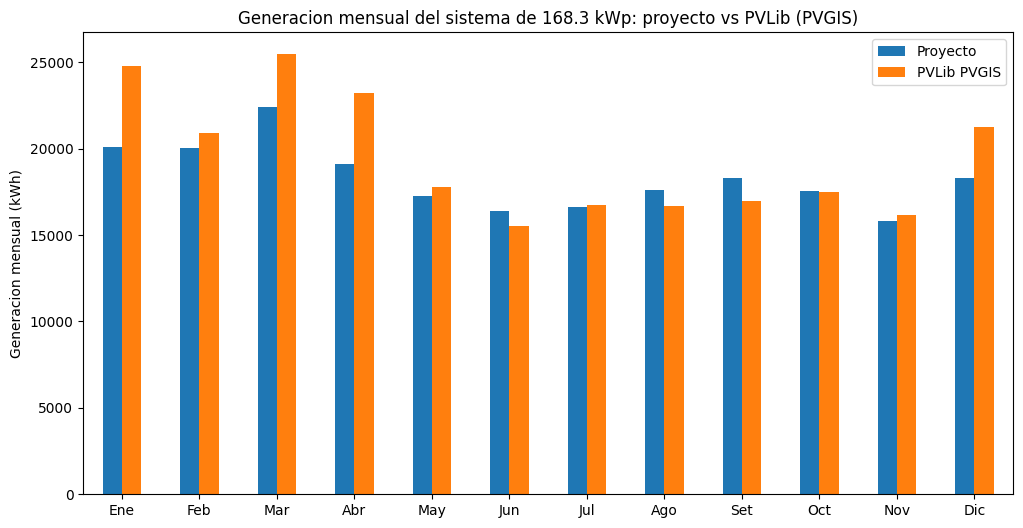

In [26]:
comparison.loc[months, ['Proyecto', 'PVLib PVGIS']].plot(kind='bar', rot=0, figsize=(12, 6))
plt.ylabel('Generacion mensual (kWh)')
plt.title('Generacion mensual del sistema de 168.3 kWp: proyecto vs PVLib (PVGIS)')
plt.savefig('comparacion_generacion_mensual.png', dpi=200, bbox_inches='tight')
comparison.to_csv('comparacion_generacion_mensual.csv')